# Лабораторная работа №1. Сбор, визуализация и анализ данных по графу

Тема: распознавание и перевод жестовых языков (sign language).

In [1]:
import os
import re
import requests
import xml.etree.ElementTree as ET
from collections import Counter
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

import nltk
from nltk.corpus import stopwords, wordnet as wn
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer

for package in ["stopwords", "wordnet", "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(package, quiet=True)

pd.set_option("display.max_colwidth", 100)

## 1–2. Сбор данных

Скачиваем через arXiv API 400 самых свежих статей, в аннотации которых есть "sign language" (с 2020 года). Сохраняем в csv, чтобы при перезапуске не скачивать заново.

In [2]:
def load_arxiv(query, n):
    params = {"search_query": query, "start": 0, "max_results": n,
              "sortBy": "submittedDate", "sortOrder": "descending"}
    response = requests.get("https://export.arxiv.org/api/query", params=params, timeout=120)
    ns = {"a": "http://www.w3.org/2005/Atom"}
    rows = []
    for entry in ET.fromstring(response.content).findall("a:entry", ns):
        rows.append({
            "id": entry.find("a:id", ns).text.split("/abs/")[-1],
            "published": entry.find("a:published", ns).text,
            "title": " ".join(entry.find("a:title", ns).text.split()),
            "authors": ", ".join(a.find("a:name", ns).text for a in entry.findall("a:author", ns)),
            "summary": " ".join(entry.find("a:summary", ns).text.split()),
        })
    return pd.DataFrame(rows)


if os.path.exists("arxiv_sign_language.csv"):
    df = pd.read_csv("arxiv_sign_language.csv")
else:
    df = load_arxiv('abs:"sign language" AND submittedDate:[202001010000 TO 202609242359]', 400)
    df.to_csv("arxiv_sign_language.csv", index=False)

df["published"] = pd.to_datetime(df["published"]).dt.tz_localize(None)
print(df.shape)
print("Период:", df["published"].min().date(), "—", df["published"].max().date())
df.head()

(400, 5)
Период: 2024-06-11 — 2026-09-24


,id,published,title,authors,summary
0,2609.29292v1,2026-09-24 09:27:47,PHOSA: Photorealistic 3D Sign Avatar Modeling and Benchmark,"Haodong Wang, Hezhen Hu, Wengang Zhou, Houqiang Li","In this work, we focus on photorealistic sign avatar modeling, which is crucial for effective communication with the Deaf community and is characterized by complex hand gestures and nuanced facial expressions. To this end, we introduce MVSign, the first multi-view Chinese sign language dataset co-designed with Deaf experts, featuring diverse gestures and rich annotations. For precise SMPL-X annotation, we develop a hybrid fitting pipeline that produces accurate body, hand, and facial parameters and can also be applied to the monocular setting. Building on MVSign, we propose a decoupled sign avatar representation that isolates body, head, and hand components to capture complex articulations, together with a motion-aware sampling strategy to handle motion blur and balance gesture diversity. Extensive experiments demonstrate that our method achieves high-fidelity visual results on MVSign, particularly in detailed hand and facial regions, and generalizes well to in-the-wild monocular sign language videos. Project page: https://naaapi.github.io/PHOSA."
1,2609.25862v1,2026-09-22 08:26:36,Isolated Sign Language Recognition for Icelandic Sign Language: Experiments in a Low-resource Setting,"Finnur Ágúst Ingimundarson, Guðný Björk Þorvaldsdóttir, Mathias Müller, Sarah Ebling","We present the first experiments on isolated sign language recognition (ISLR) for Icelandic Sign Language (ÍTM). We use ÍTM SignWiki, a dataset derived from a bilingual Icelandic--ÍTM online dictionary. It is genuinely low-resource: 1,845 videos cover 849 classes, 86% of which have only two examples, making the full task effectively one-shot recognition across signers. We compare two open-source ISLR frameworks, OpenHands and SPOTER, on three tasks of increasing vocabulary size (22, 117 and 849 classes), and evaluate three pose estimators and two forms of cross-lingual transfer. With ÍTM data alone, SPOTER outperforms OpenHands on all three tasks, and MediaPipe poses give better results than AlphaPose or SDPose. Cross-lingual transfer brings the largest gains: pretraining SPOTER on American Sign Language data before finetuning on ÍTM raises accuracy by 14--24 percentage points, to 72.7%, 47.9% and 22.6% on the three tasks, and multilingual training with data from six other sign languages lifts OpenHands from 1.41% to 28.86% on the full task. Although far from practical use, the results suggest that transfer from better-resourced sign languages is promising for very low-resource ones. We release our adapted versions of both frameworks."
2,2609.21709v1,2026-09-18 12:46:50,SignGPT: Toward LLM-Mediated Sign Language Interaction through Gloss-Free Translation and Generation,"Ronghui Li, Jun Dong, Zhongyuan Hu, Zunnan Xu, Jun Zhou, Liyuan Chen, Shuoling Liu, Jiangpeng Yan, Jie Guo, Xiu Li, Linchao Bao","Large language models (LLMs) provide limited support for sign language interaction. Unifying sign language translation (SLT) and generation (SLG) to enable sign language as both input and output can reduce switching between separate models during sign-text interaction. We present SignGPT, a unified, pose-based framework for gloss-free SLT and SLG. SignGPT integrates part-aware hierarchical representations of body, hand, and facial motion into a shared language model and employs asymmetric multi-token prediction and progressive training for bidirectional modeling. We evaluate SignGPT on How2Sign (ASL) and Phoenix-2014T (DGS) through benchmark comparisons, qualitative analyses, and component ablations. An exploratory study with 12 Deaf ASL signers assesses an LLM-mediated sign-to-sign response pipeline, highlighting the potential of unified modeling to support sign language conversation (SLC)."
3,2609.18772v1,2026-09-16 14:56:51,Zero-Shot Cross-Lingual Recognition of Sign Language Handshape

## 3. Разведочный анализ

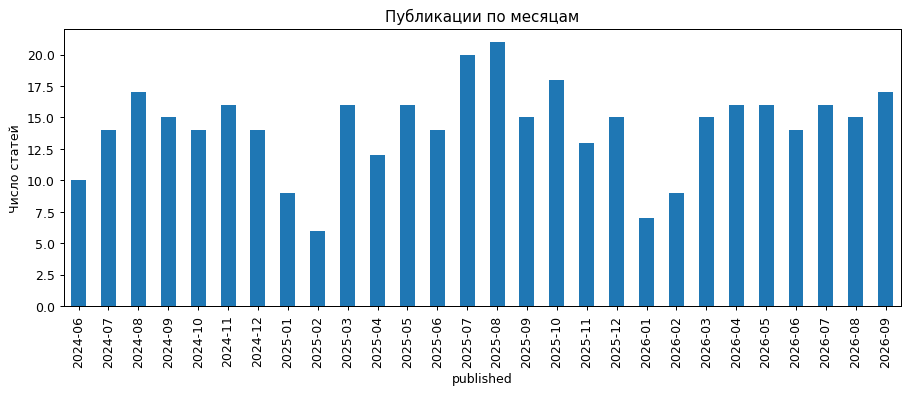

In [3]:
df["published"].dt.to_period("M").value_counts().sort_index().plot(kind="bar", figsize=(12, 4))
plt.title("Публикации по месяцам")
plt.ylabel("Число статей")
plt.show()

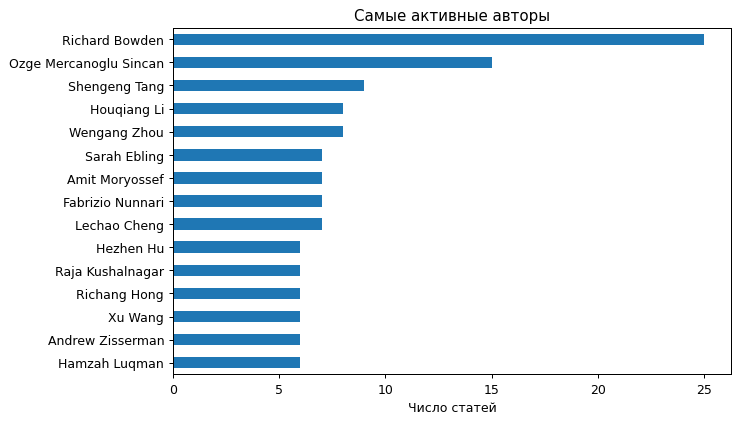

In [4]:
authors = Counter(a for line in df["authors"] for a in line.split(", "))
pd.Series(dict(authors.most_common(15))).sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("Самые активные авторы")
plt.xlabel("Число статей")
plt.show()

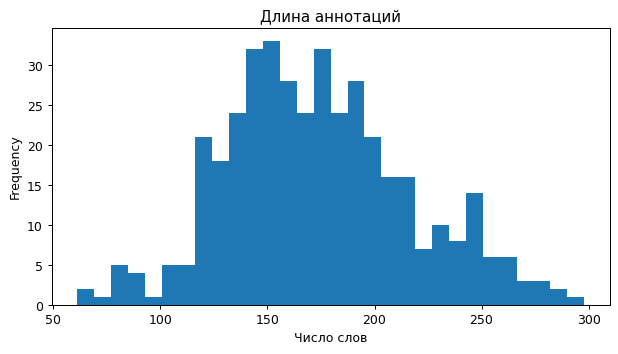

In [5]:
df["summary"].str.split().str.len().plot(kind="hist", bins=30, figsize=(8, 4))
plt.title("Длина аннотаций")
plt.xlabel("Число слов")
plt.show()

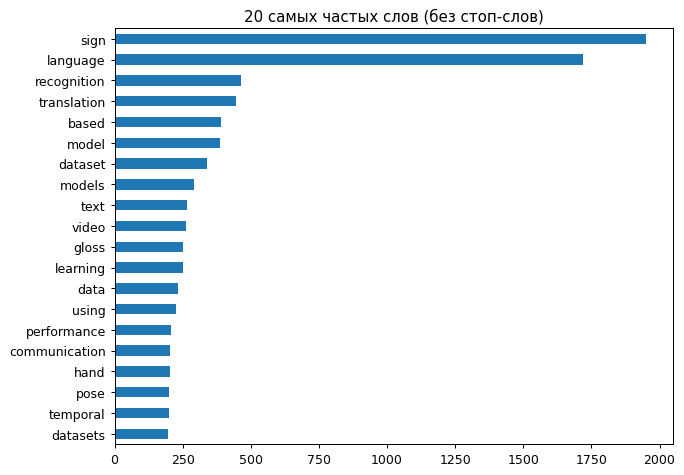

In [6]:
df["text"] = (df["title"] + ". " + df["summary"]).str.lower().str.replace("*", "", regex=False)
all_words = re.findall(r"[a-z]+", " ".join(df["text"]))
stop_words = set(stopwords.words("english"))

top_words = Counter(w for w in all_words if w not in stop_words).most_common(20)
pd.Series(dict(top_words)).sort_values().plot(kind="barh", figsize=(8, 6))
plt.title("20 самых частых слов (без стоп-слов)")
plt.show()

Чаще всего встречаются sign и language — это название темы, поэтому дальше их убираем.

Проверка закона Ципфа: частота слова ~ 1 / ранг, в log-log осях должна получиться прямая с наклоном около -1.

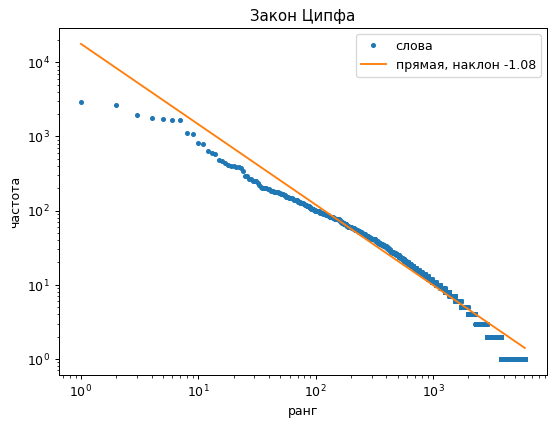

наклон: -1.08


In [7]:
freq = np.array(sorted(Counter(all_words).values(), reverse=True))
rank = np.arange(1, len(freq) + 1)
k, b = np.polyfit(np.log(rank[freq >= 3]), np.log(freq[freq >= 3]), 1)

plt.figure(figsize=(7, 5))
plt.loglog(rank, freq, ".", label="слова")
plt.loglog(rank, np.exp(b) * rank ** k, label=f"прямая, наклон {k:.2f}")
plt.xlabel("ранг")
plt.ylabel("частота")
plt.title("Закон Ципфа")
plt.legend()
plt.show()
print("наклон:", round(k, 2))

Вывод: закон Ципфа выполняется. Точки почти лежат на прямой, наклон -1.08, это близко к -1. Отклонения есть только у самых частых слов (the, and, of) и в хвосте, где много слов встречается по 1–2 раза.

Проверка закона Хипса: число разных слов V растёт медленнее, чем длина текста N: V ≈ K · N^β, где β обычно от 0.4 до 0.7. Идём по корпусу слово за словом и после каждого слова записываем, сколько разных слов уже встретилось.

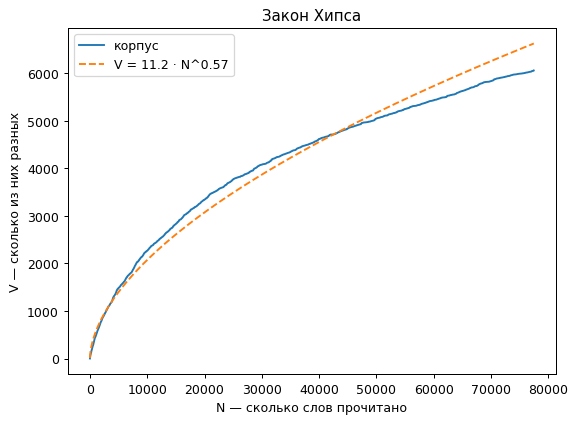

K = 11.2 ; beta = 0.57


In [8]:
seen, n_tokens, n_unique = set(), [], []
for i, w in enumerate(all_words, start=1):
    seen.add(w)
    n_tokens.append(i)
    n_unique.append(len(seen))
n_tokens, n_unique = np.array(n_tokens), np.array(n_unique)
beta, log_k = np.polyfit(np.log(n_tokens), np.log(n_unique), 1)

plt.figure(figsize=(7, 5))
plt.plot(n_tokens, n_unique, label="корпус")
plt.plot(n_tokens, np.exp(log_k) * n_tokens ** beta, "--", label=f"V = {np.exp(log_k):.1f} · N^{beta:.2f}")
plt.xlabel("N — сколько слов прочитано")
plt.ylabel("V — сколько из них разных")
plt.title("Закон Хипса")
plt.legend()
plt.show()
print("K =", round(np.exp(log_k), 1), "; beta =", round(beta, 2))

Вывод: закон Хипса выполняется. Число разных слов растёт всё медленнее, β = 0.57 — это обычный диапазон для текстов (0.4–0.7). То есть словарь корпуса продолжает пополняться, но каждая новая статья приносит всё меньше новых слов. В конце кривая идёт чуть ниже аппроксимации: все статьи на одну тему, поэтому новых слов к концу становится ещё меньше.

## 4. Ключевые слова

Берём название + аннотацию. Кандидаты в ключевые слова — существительные и словосочетания из 2–3 слов, которые заканчиваются на существительное (перед ним могут стоять прилагательные и другие существительные: hand gesture, graph convolutional network). Поэтому глаголы вроде achieve и одиночные прилагательные вроде novel ключевыми словами не становятся. Слова приводим к начальной форме и убираем стоп-слова, в том числе слова темы (sign, language) и самые общие слова научных статей.

Потом по TF-IDF для каждой статьи берём 3 лучших слова, 2 лучших биграммы и 1 лучшую триграмму.

In [9]:
stop_words |= {"sign", "signer", "language", "sign-language", "paper", "work", "study", "approach", "method",
               "model", "result", "task", "performance", "experiment", "framework", "system", "data", "set",
               "time", "example", "number", "use", "way", "need", "leverage", "state-of-the-art",
               "new", "novel", "different", "current", "existing", "various", "present", "future"}
lemmatizer = WordNetLemmatizer()


def is_noun(word):
    # слово бывает существительным или его нет в словаре (например, llm, bleu)
    return bool(wn.synsets(word, pos="n")) or not wn.synsets(word)


def extract_terms(text):
    # слова и словосочетания из 1–3 слов, которые заканчиваются на существительное
    tokens = re.findall(r"[a-z]+(?:-[a-z]+)*|[.,;:()]", text.lower())
    terms, phrase = [], []  # phrase — подряд идущие прилагательные и существительные
    for w, tag in nltk.pos_tag(tokens):
        w = lemmatizer.lemmatize(w)
        if w in stop_words or len(w) < 3:
            phrase = []
        elif tag.startswith("NN") and is_noun(w):
            phrase.append(w)
            for n in (1, 2, 3):  # слово + словосочетания, которые на нём заканчиваются
                if len(phrase) >= n:
                    terms.append(" ".join(phrase[-n:]))
        elif tag.startswith("JJ"):
            phrase.append(w)
        else:
            phrase = []
    return terms


df["terms"] = df["text"].apply(extract_terms)
print(df["terms"][0][:24])

['phosa', 'avatar', 'modeling', 'avatar modeling', 'benchmark', 'avatar', 'modeling', 'avatar modeling', 'communication', 'effective communication', 'deaf', 'community', 'deaf community', 'hand', 'complex hand', 'gesture', 'hand gesture', 'complex hand gesture', 'expression', 'facial expression', 'nuanced facial expression', 'end', 'multi-view', 'first multi-view']


In [10]:
vectorizer = TfidfVectorizer(analyzer=lambda terms: terms, min_df=3, max_df=0.5)
X = vectorizer.fit_transform(df["terms"])
vocab = vectorizer.get_feature_names_out()
term_len = np.array([len(t.split()) for t in vocab])  # сколько слов в термине


def top_keywords(i):
    # по TF-IDF: 3 лучших слова, 2 лучших биграммы и 1 лучшая триграмма
    row = X[i].toarray().ravel()
    keywords = []
    for n, k in [(1, 3), (2, 2), (3, 1)]:
        idx = np.where((row > 0) & (term_len == n))[0]
        best = idx[np.argsort(-row[idx], kind="stable")][:k]  # stable: при равных весах по алфавиту
        keywords += [vocab[j] for j in best]
    return keywords


df["keywords"] = [top_keywords(i) for i in range(len(df))]
df[["title", "keywords"]].head(10)

,title,keywords
0,PHOSA: Photorealistic 3D Sign Avatar Modeling and Benchmark,"[avatar, hand, gesture, complex hand, motion blur]"
1,Isolated Sign Language Recognition for Icelandic Sign Language: Experiments in a Low-resource Setting,"[transfer, islr, class, cross-lingual transfer, percentage point]"
2,SignGPT: Toward LLM-Mediated Sign Language Interaction through Gloss-Free Translation and Generation,"[slg, interaction, modeling, facial motion, qualitative analysis]"
3,Zero-Shot Cross-Lingual Recognition of Sign Language Handshapes,"[handshapes, handshape, asl, handshape recognition]"
4,SignMimic: Robust High-Quality Sign Language Motion Generation via Human-Shape-Oblivious Pose Transfer Guidance,"[video, identity, adaptation, single reference, video diffusion]"
5,Investigating Temporal Motion Features for Pose-to-Text Indian Sign Language Translation,"[motion, bleu, score, motion feature, pose encoder]"
6,Learning Sign Language Recognition under Label Noise: A Study of Noise-Robust Losses for Isolated and Continuous Settings,"[noise, loss, gradient, temporal boundary, temporal classification, word error rate]"
7,SignRefine: Adapting Foundational Video Models for Sign Language Generation,"[video, articulation, appearance, video diffusion, video generation]"
8,Rethinking Sign Language Translation: The Impact of Signer Dependence on Model Evaluation,"[sentence, evaluation, generalisation, gloss-free slt, deep learning]"
9,RAIDAL: Redundancy-Aware Information Density Active Learning for CTC-Based Continuous Sign Language Recognition,"[acquisition, function, cost, continuous video, gloss sequence]"


Всего разных ключевых слов: 808
Из них по числу слов (1, 2, 3): {1: 467, 2: 328, 3: 13}


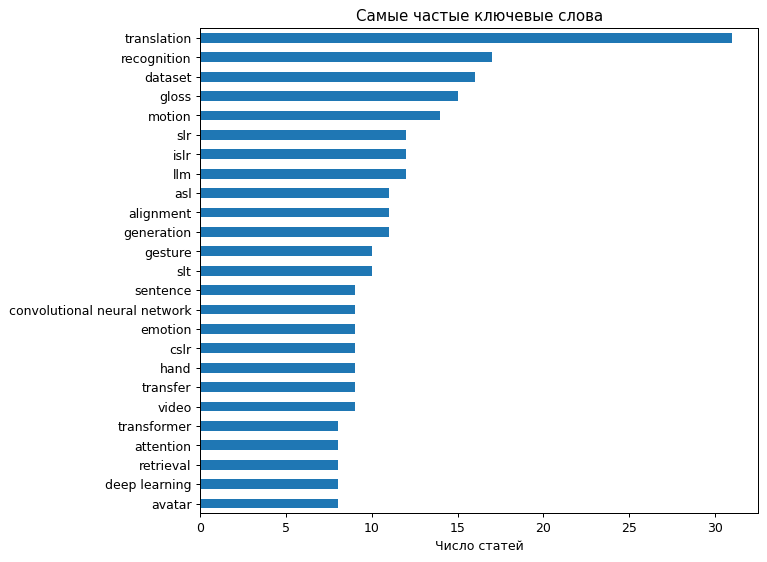

In [11]:
keyword_counts = Counter(k for kws in df["keywords"] for k in kws)
print("Всего разных ключевых слов:", len(keyword_counts))
print("Из них по числу слов (1, 2, 3):", dict(sorted(Counter(len(k.split()) for k in keyword_counts).items())))
pd.Series(dict(keyword_counts.most_common(25))).sort_values().plot(kind="barh", figsize=(8, 7))
plt.title("Самые частые ключевые слова")
plt.xlabel("Число статей")
plt.show()

## 5. Граф ключевых слов

Вершины — ключевые слова, ребро — слова встретились у одной статьи, вес — у скольких статей. Слова, которые есть только у одной статьи, не берём.

In [12]:
G = nx.Graph()
for kws in df["keywords"]:
    kws = [k for k in kws if keyword_counts[k] >= 2]
    for a, b in combinations(kws, 2):
        if G.has_edge(a, b):
            G[a][b]["weight"] += 1
        else:
            G.add_edge(a, b, weight=1)

degrees = dict(G.degree())
print("Вершин:", G.number_of_nodes())
print("Рёбер:", G.number_of_edges())
print("Плотность:", round(nx.density(G), 4))
print("Средняя степень:", round(np.mean(list(degrees.values())), 1))

Вершин: 499
Рёбер: 2734
Плотность: 0.022
Средняя степень: 11.0


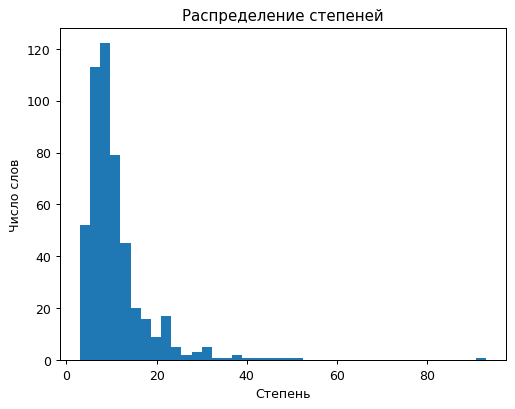

In [13]:
plt.hist(list(degrees.values()), bins=40)
plt.title("Распределение степеней")
plt.xlabel("Степень")
plt.ylabel("Число слов")
plt.show()

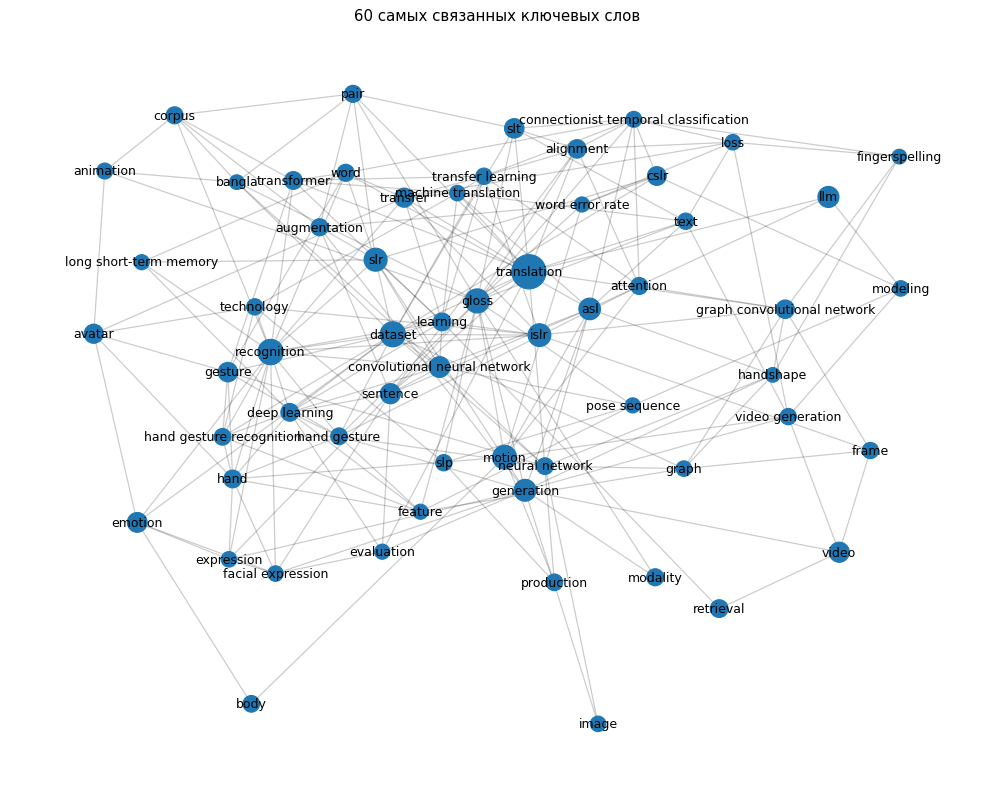

In [14]:
top_nodes = sorted(G, key=degrees.get, reverse=True)[:60]
H = G.subgraph(top_nodes)
pos = nx.spring_layout(H, weight="weight", seed=42, k=0.6, iterations=200)

plt.figure(figsize=(14, 11))
nx.draw_networkx_edges(H, pos, alpha=0.2)
nx.draw_networkx_nodes(H, pos, node_size=[degrees[n] * 8 for n in H])
nx.draw_networkx_labels(H, pos, font_size=10)
plt.title("60 самых связанных ключевых слов")
plt.axis("off")
plt.show()

## 6. Кластеры

In [15]:
communities = nx.community.louvain_communities(G, weight="weight", seed=42)
communities = sorted(communities, key=len, reverse=True)
print("Кластеров:", len(communities))
print("Модулярность:", round(nx.community.modularity(G, communities, weight="weight"), 3))

cluster_of = {w: i for i, c in enumerate(communities) for w in c}
weighted_degree = dict(G.degree(weight="weight"))
pd.DataFrame({
    "размер": [len(c) for c in communities],
    "главные слова": [", ".join(sorted(c, key=lambda w: (-weighted_degree[w], w))[:12]) for c in communities],
})

Кластеров: 13
Модулярность: 0.441


,размер,главные слова
0,79,"motion, generation, video, cslr, video generation, body, word error rate, image, diffusion, modeling, clip, real-world application"
1,59,"recognition, dataset, islr, hand gesture recognition, gesture, deep learning, hand gesture, transfer, hand, learning, transformer, transfer learning"
2,47,"emotion, sentence, avatar, expression, facial expression, modality, animation, automatic speech recognition, dialogue, emotional expression, signal, speech recognition"
3,45,"llm, dhh community, tool, communication, user, dhh, learner, assistive technology, people, asl communication, design implication, design recommendation"
4,43,"translation, production, evaluation, fusion, evaluation metric, reference, content, transformer architecture, deaf community, deep neural network, generation quality, metric"
5,40,"asl, graph convolutional network, attention, neural network, handshape, graph, lstm, fingerspelling, network, annotation, keypoints, bsl"
6,35,"corpus, augmentation, pair, frame, bangla, human motion, bdsl, inertial measurement unit, parallel corpus, transformation, activity recognition, bdslw"
7,33,"slp, technology, slu, description, processing, consistency, accurate translation, knowledge transfer, signing, pre-training, mllms, self-supervised representation"
8,32,"retrieval, representation, encoder, bleu, rgb, space, motion representation, reconstruction, gloss attention, learned representation, pose encoder, body part"
9,31,"gloss, slt, alignment, connectionist temporal classification, text, loss, segment, cue, gloss translation, gloss-free slt, spoken text, contrastive objective"


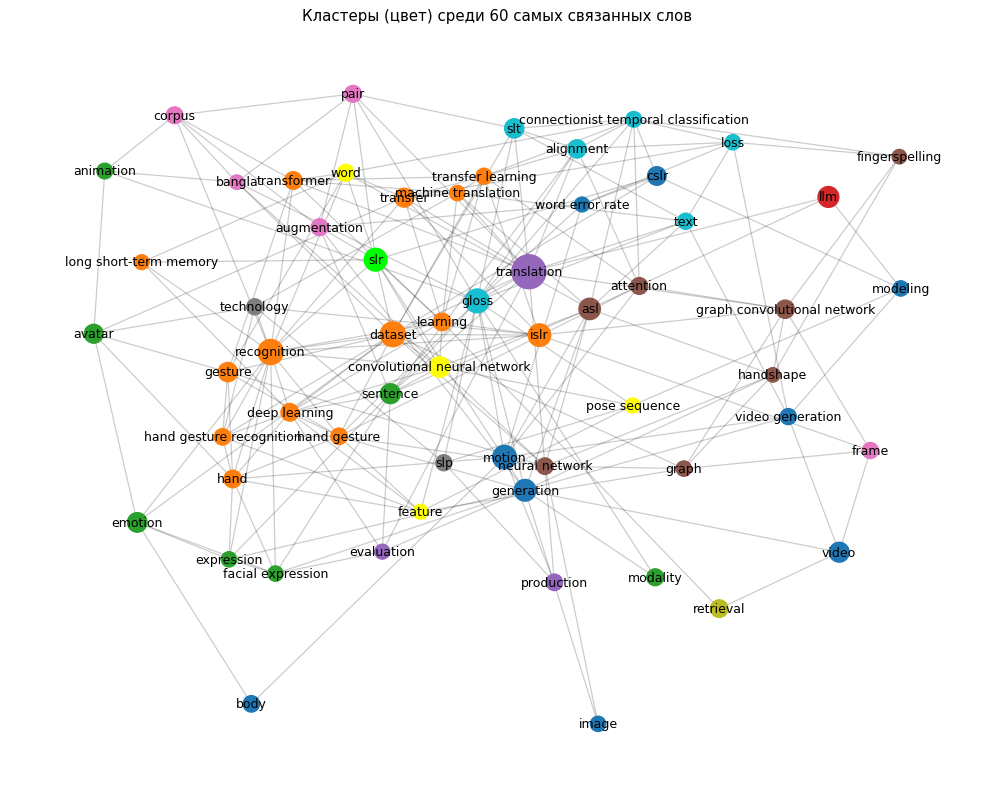

In [16]:
colors = list(plt.cm.tab10.colors) + ["yellow", "lime", "black"]  # 13 цветов, по одному на кластер
plt.figure(figsize=(14, 11))
nx.draw_networkx_edges(H, pos, alpha=0.2)
nx.draw_networkx_nodes(H, pos, node_size=[degrees[n] * 8 for n in H], node_color=[colors[cluster_of[n]] for n in H])
nx.draw_networkx_labels(H, pos, font_size=10)
plt.title("Кластеры (цвет) среди 60 самых связанных слов")
plt.axis("off")
plt.show()

Модулярность 0.44 (больше 0.3), значит кластерная структура есть. Теперь среди ключевых слов много биграмм и триграмм, поэтому кластеров стало больше и они мельче, их 13.

Кластеры по смыслу:
- 0 — генерация движений и видео (motion, generation, video generation, diffusion);
- 1 — распознавание жестов глубоким обучением (recognition, islr, hand gesture recognition, deep learning, transfer learning);
- 2 — эмоции, мимика и аватары (emotion, facial expression, avatar, animation);
- 3 — люди и доступность: инструменты для глухих и пользовательские исследования (dhh community, tool, assistive technology, design recommendation, llm);
- 4 — перевод и генерация, оценка качества (translation, production, evaluation metric, generation quality);
- 5 — архитектуры для распознавания по ключевым точкам, формы кисти и дактилология (graph convolutional network, lstm, attention, handshape, fingerspelling);
- 6 — корпуса и данные (corpus, parallel corpus, augmentation, bangla, inertial measurement unit);
- 7 — предобучение и «понимание» жестового языка (slu, pre-training, mllms, self-supervised representation);
- 8 — обучение представлений и поиск (representation, encoder, retrieval, pose encoder);
- 9 — перевод через глоссы и без них (gloss, slt, alignment, connectionist temporal classification, gloss-free slt);
- 10 — распознавание по позе с помощью CNN (convolutional neural network, pose estimation, pose sequence);
- 11 — лёгкие модели для слабых устройств (bidirectional reservoir computing, edge device);
- 12 — event-камеры и скелет (event camera, bone, joint position).

## 7. Центральность

In [17]:
centrality = pd.DataFrame({
    "degree": nx.degree_centrality(G),
    "betweenness": nx.betweenness_centrality(G),
    "closeness": nx.closeness_centrality(G),
    "eigenvector": nx.eigenvector_centrality(G, weight="weight", max_iter=1000),
})
pd.DataFrame({m: centrality[m].sort_values(ascending=False).head(10).index for m in centrality}, index=range(1, 11))

,degree,betweenness,closeness,eigenvector
1,translation,translation,translation,recognition
2,recognition,dataset,dataset,translation
3,dataset,recognition,recognition,hand gesture recognition
4,gloss,motion,gloss,dataset
5,motion,slr,slr,hand gesture
6,slr,gloss,asl,deep learning
7,islr,islr,generation,hand
8,generation,generation,transfer,gloss
9,asl,asl,motion,gesture
10,llm,llm,convolutional neural network,learning


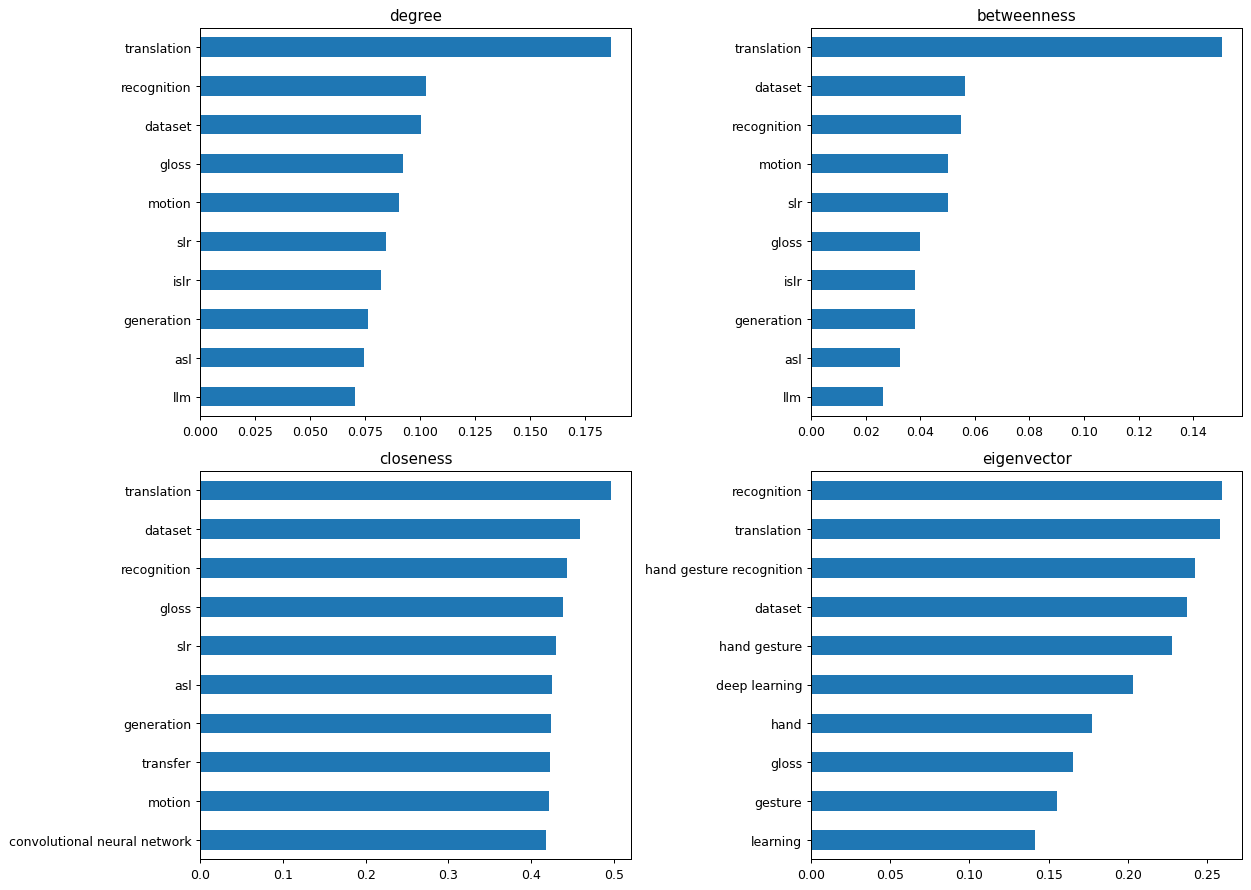

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, m in zip(axes.ravel(), centrality.columns):
    centrality[m].sort_values().tail(10).plot(kind="barh", ax=ax, title=m)
plt.tight_layout()
plt.show()

Во всех метриках вверху translation, recognition и dataset: это основные направления — перевод, распознавание и сбор датасетов. По eigenvector вверх поднимаются hand gesture recognition, hand gesture и deep learning: самое плотное ядро графа образуют работы по распознаванию жестов рук. По betweenness высоко стоят slr, gloss и asl — это слова-«мосты» между подтемами.

## 8. Граф публикаций

Вершины — статьи, ребро — есть общие ключевые слова, вес — сколько их.

In [19]:
kw_sets = [set(k) for k in df["keywords"]]
P = nx.Graph()
P.add_nodes_from(df.index)
for i, j in combinations(df.index, 2):
    common = len(kw_sets[i] & kw_sets[j])
    if common > 0:
        P.add_edge(i, j, weight=common)

print("Вершин:", P.number_of_nodes())
print("Рёбер:", P.number_of_edges())
print("Средняя степень:", round(np.mean([d for _, d in P.degree()]), 1))
print("Веса рёбер:", Counter(d["weight"] for _, _, d in P.edges(data=True)))

Вершин: 400
Рёбер: 3326
Средняя степень: 16.6
Веса рёбер: Counter({1: 3153, 2: 146, 3: 26, 5: 1})


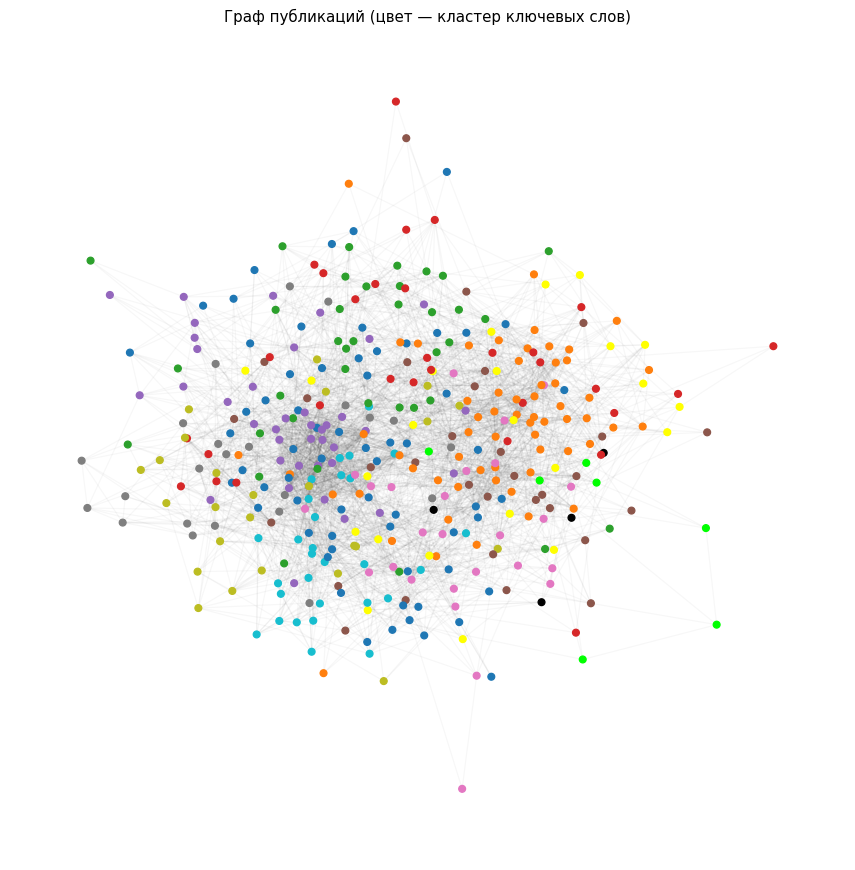

In [20]:
# цвет статьи — кластер, к которому относится больше всего её ключевых слов
paper_cluster = [Counter(cluster_of[k] for k in kws if k in cluster_of).most_common(1)[0][0]
                 if any(k in cluster_of for k in kws) else 0 for kws in df["keywords"]]
pos_p = nx.spring_layout(P, weight="weight", seed=42)
plt.figure(figsize=(12, 12))
nx.draw_networkx_edges(P, pos_p, alpha=0.03)
nx.draw_networkx_nodes(P, pos_p, node_size=30, node_color=[colors[c] for c in paper_cluster])
plt.title("Граф публикаций (цвет — кластер ключевых слов)")
plt.axis("off")
plt.show()

### Как работает поиск похожих статей

Самый простой вариант — взять соседей статьи в графе и отсортировать их по числу общих ключевых слов. Но у него два минуса: у многих соседей одинаковое число общих слов (большинство рёбер имеют вес 1), и он не находит статьи, с которыми у запроса нет общих слов.

Поэтому я использую **Personalized PageRank** — случайное блуждание по графу с возвратом:
1. Начинаем в статье-запросе.
2. На каждом шаге с вероятностью 0.5 переходим в соседнюю статью (в ту, с которой больше общих слов, — чаще), а с вероятностью 0.5 возвращаемся в статью-запрос.
3. Score статьи — доля времени, которую блуждание проводит в ней.

Чем больше коротких путей ведёт от запроса к статье и чем тяжелее на них рёбра, тем выше score. Поэтому сверху оказываются соседи с большим числом общих слов, а дальше могут идти и статьи в 2 шагах, у которых с запросом нет общих слов, но много общих соседей.

В таблице: `score` — близость к запросу, `общих слов` — сколько общих ключевых слов с запросом, `шагов` — расстояние по графу (1 — прямой сосед, 2 — сосед соседа).

In [21]:
def similar_papers(i, top_n=10):
    scores = pd.Series(nx.pagerank(P, alpha=0.5, personalization={i: 1}, weight="weight"))
    scores = scores.drop(i).sort_values(ascending=False).head(top_n)
    print(df.at[i, "title"], df.at[i, "keywords"])
    return pd.DataFrame({
        "score": scores.round(4),
        "общих слов": [len(kw_sets[i] & kw_sets[j]) for j in scores.index],
        "шагов": [nx.shortest_path_length(P, i, j) for j in scores.index],
        "title": df.loc[scores.index, "title"],
    })


similar_papers(0)

PHOSA: Photorealistic 3D Sign Avatar Modeling and Benchmark ['avatar', 'hand', 'gesture', 'complex hand', 'motion blur']


,score,общих слов,шагов,title
122,0.0267,2,1,VGG Induced Deep Hand Sign Language Detection
292,0.0167,1,1,Survey on Hand Gesture Recognition from Visual Input
137,0.0158,1,1,A Comparative Study of EMG- and IMU-based Gesture Recognition at the Wrist and Forearm
372,0.0150,1,1,An Advanced Deep Learning Based Three-Stream Hybrid Model for Dynamic Hand Gesture Recognition
97,0.0150,1,1,Dynamic LIBRAS Gesture Recognition via CNN over Spatiotemporal Matrix Representation
387,0.0134,1,1,Sign Language Recognition Based On Facial Expression and Hand Skeleton
236,0.0134,1,1,Synthetic Human Action Video Data Generation with Pose Transfer
73,0.0132,1,1,Low Resource Multimodal Translation of Nepali Spoken Words into Emotion-Conditioned Sign Language Avatars
375,0.0132,1,1,Using CSNNs to Perform Event-based Data Processing & Classification on ASL-DVS
252,0.0131,1,1,TSLFormer: A Lightweight Transformer Model for Turkish Sign Language Recognition Using Skeletal Landmarks


Для статьи про 3D-аватары на первом месте VGG Induced Deep Hand Sign Language Detection (2 общих слова: hand и gesture), дальше статьи про распознавание жестов рук.

## 9. Поиск по запросу и тесты

Поиск по текстовому запросу — то же самое блуждание, только начинаем не с одной статьи, а со всех статей, где есть слова запроса:
1. Из запроса достаём слова и словосочетания той же функцией `extract_terms`, что и для статей.
2. Находим статьи, у которых они есть среди ключевых слов, — это стартовые статьи. Чем реже слово, тем больше вес у статьи с ним (сумма idf совпавших слов): bangla важнее, чем recognition.
3. Запускаем Personalized PageRank, который возвращается в стартовые статьи, и берём статьи с самым большим score.

Колонка `есть слово запроса` показывает, нашлась ли статья напрямую (True) или только через граф (False).

In [22]:
idf = dict(zip(vocab, vectorizer.idf_))


def search(query, top_n=10):
    query_terms = set(extract_terms(query))
    # вес стартовой статьи — сумма idf совпавших слов: редкие слова запроса важнее частых
    seeds = {i: sum(idf[t] for t in query_terms & kw_sets[i]) for i in df.index if query_terms & kw_sets[i]}
    print("Слова запроса:", sorted(query_terms & set(keyword_counts)), "; статей с ними:", len(seeds))
    scores = pd.Series(nx.pagerank(P, alpha=0.5, personalization=seeds, weight="weight"))
    scores = scores.sort_values(ascending=False).head(top_n)
    return pd.DataFrame({
        "score": scores.round(4),
        "есть слово запроса": [i in seeds for i in scores.index],
        "title": df.loc[scores.index, "title"],
    })

In [23]:
search("sign language translation with large language models (LLM)")

Слова запроса: ['llm', 'translation'] ; статей с ними: 42


,score,есть слово запроса,title
150,0.0417,True,Large Sign Language Models: Toward 3D American Sign Language Translation
324,0.0262,True,LLM-Powered AI Tutors with Personas for d/Deaf and Hard-of-Hearing Online Learners
322,0.0261,True,Enhanced Sign Language Translation between American Sign Language (ASL) and Indian Sign Language (ISL) Using LLMs
47,0.0261,True,ViPo-MLLM: Visual-Pose Multimodal LLM for Gloss-Free Sign Language Translation
302,0.0258,True,LLaVA-SLT: Visual Language Tuning for Sign Language Translation
28,0.0257,True,SignLlama: Enhancing Gloss-free Sign Language Translation by Prioritizing Visual Features for LLMs
102,0.0257,True,SignAgent: Agentic LLMs for Linguistically-Grounded Sign Language Annotation and Dataset Curation
34,0.0256,True,DualAnchor: Preserving Language Priors and Improving Lexical Fidelity in Gloss-Free Sign Language Translation
215,0.0256,True,Teach Me Sign: Stepwise Prompting LLM for Sign Language Production
224,0.0254,True,Sign Spotting Disambiguation using Large Language Models


In [24]:
search("3D avatar animation")

Слова запроса: ['animation', 'avatar'] ; статей с ними: 13


,score,есть слово запроса,title
221,0.0959,True,VisualSpeaker: Visually-Guided 3D Avatar Lip Synthesis
146,0.0516,True,IsharaKotha: A Comprehensive Avatar-based Bangla Sign Language Corpus
220,0.0514,True,Speak2Sign3D: A Multi-modal Pipeline for English Speech to American Sign Language Animation
73,0.0507,True,Low Resource Multimodal Translation of Nepali Spoken Words into Emotion-Conditioned Sign Language Avatars
67,0.0507,True,KAN Text to Vision? The Exploration of Kolmogorov-Arnold Networks for Multi-Scale Sequence-Based Pose Animation from Sign Language Notation
231,0.0498,True,Human-Centered Editable Speech-to-Sign-Language Generation via Streaming Conformer-Transformer and Resampling Hook
213,0.0480,True,MMS Player: an open source software for parametric data-driven animation of Sign Language avatars
236,0.0456,True,Synthetic Human Action Video Data Generation with Pose Transfer
0,0.0454,True,PHOSA: Photorealistic 3D Sign Avatar Modeling and Benchmark
200,0.0453,True,9th Workshop on Sign Language Translation and Avatar Technologies (SLTAT 2025)


In [25]:
search("Bangla sign language recognition")

Слова запроса: ['bangla', 'recognition'] ; статей с ними: 23


,score,есть слово запроса,title
365,0.0569,True,BAUST Lipi: A BdSL Dataset with Deep Learning Based Bangla Sign Language Recognition
151,0.0541,True,Introducing A Bangla Sentence - Gloss Pair Dataset for Bangla Sign Language Translation and Research
146,0.0538,True,IsharaKotha: A Comprehensive Avatar-based Bangla Sign Language Corpus
282,0.0510,True,BdSLW401: Transformer-Based Word-Level Bangla Sign Language Recognition Using Relative Quantization Encoding (RQE)
29,0.0507,True,Toward Deployable Bangla Sign Language Recognition with Expert-Validated Data and a Lightweight Attention-Based Model
303,0.0494,True,Real-time Bangla Sign Language Translator
166,0.0256,True,Nepali Sign Language Characters Recognition: Dataset Development and Deep Learning Approaches
329,0.0255,True,One-Stage-TFS: Thai One-Stage Fingerspelling Dataset for Fingerspelling Recognition Frameworks
148,0.0239,True,RoCoISLR: A Romanian Corpus for Isolated Sign Language Recognition
292,0.0238,True,Survey on Hand Gesture Recognition from Visual Input


In [26]:
search("question answering")

Слова запроса: ['question'] ; статей с ними: 3


,score,есть слово запроса,title
174,0.1878,True,SSL-SSAW: Self-Supervised Learning with Sigmoid Self-Attention Weighting for Question-Based Sign Language Translation
338,0.1856,True,BQA: Body Language Question Answering Dataset for Video Large Language Models
33,0.1767,True,"Sign Language Question Answering: A New Task, Benchmark, and Baseline for Sign Language Understanding"
50,0.0182,False,SIGNET: Motion-Level Knowledge Transfer for Cross-Language Sign Language Translation
286,0.0180,False,GLoT: A Novel Gated-Logarithmic Transformer for Efficient Sign Language Translation
167,0.0176,False,Saudi Sign Language Translation Using T5
291,0.0144,False,Uni-Sign: Toward Unified Sign Language Understanding at Scale
371,0.0139,False,Scaling up Multimodal Pre-training for Sign Language Understanding
63,0.0099,False,Emotion Recognition in Sign Language Conversation
157,0.0084,False,How Pragmatics Shape Articulation: A Computational Case Study in STEM ASL Discourse


In [27]:
similar_papers(22)  # статья про генерацию видео с помощью GAN, у неё мало соседей

Sign Language Video Synthesis via Loss-Guided Multi-Expert GANs ['branch', 'generator', 'synthesis', 'video synthesis', 'adversarial network', 'generative adversarial network']


,score,общих слов,шагов,title
212,0.0943,2,1,Bringing Balance to Hand Shape Classification: Mitigating Data Imbalance Through Generative Models
197,0.0941,2,1,"Generation of Indian Sign Language Letters, Numbers, and Words"
205,0.0437,1,1,Motion is the Choreographer: Learning Latent Pose Dynamics for Seamless Sign Language Generation
299,0.0436,1,1,Beyond Words: AuralLLM and SignMST-C for Sign Language Production and Bidirectional Accessibility
96,0.0073,0,2,FlashSign: Pose-Free Guidance for Efficient Sign Language Video Generation
232,0.0061,0,2,StgcDiff: Spatial-Temporal Graph Condition Diffusion for Sign Language Transition Generation
119,0.0059,0,2,MaDiS: Taming Masked Diffusion Language Models for Sign Language Generation
288,0.0059,0,2,Towards AI-driven Sign Language Generation with Non-manual Markers
183,0.0059,0,2,SiLVERScore: Semantically-Aware Embeddings for Sign Language Generation Evaluation
139,0.0059,0,2,Stable Signer: Hierarchical Sign Language Generative Model


Поиск работает: по LLM и переводу находятся статьи про перевод с помощью LLM, по аватарам — про аватары, по Bangla первые 6 статей — про бенгальский жестовый язык.

Для "question answering" прямых совпадений всего 3, остальные статьи найдены через граф: слова question у них нет, но это работы про перевод и «понимание» жестового языка (например, Uni-Sign и Scaling up Multimodal Pre-training for Sign Language Understanding). У статьи про генерацию видео с помощью GAN 4 прямых соседа, а дальше идут статьи в 2 шагах без общих слов, но тоже про генерацию жестового языка (FlashSign, StgcDiff, MaDiS).

Простая автоматическая проверка: доля найденных статей из того же кластера, что и запрос, по сравнению со случайной выдачей.

In [28]:
rng = np.random.default_rng(42)
graph_hits, random_hits = [], []
for i in df.index:
    scores = pd.Series(nx.pagerank(P, alpha=0.5, personalization={i: 1}, weight="weight")).drop(i)
    found = scores.sort_values(ascending=False).index[:5]
    graph_hits.append(np.mean([paper_cluster[j] == paper_cluster[i] for j in found]))
    random_hits.append(np.mean([paper_cluster[j] == paper_cluster[i] for j in rng.choice(len(df), 5)]))
print("поиск по графу:", round(np.mean(graph_hits), 2), "; случайно:", round(np.mean(random_hits), 2))

поиск по графу: 0.54 ; случайно: 0.11


54% против 11%: поиск по графу примерно в 5 раз лучше случайной выдачи.

## Правки после защиты

1. Добавил проверку закона Хипса (часть 3): β = 0.57, закон выполняется.
2. Ключевые слова теперь явно включают биграммы и триграммы. Кандидаты — слова и словосочетания до 3 слов, которые заканчиваются на существительное (перед ним могут стоять прилагательные: graph convolutional network), и для каждой статьи по TF-IDF берутся 3 слова, 2 биграммы и 1 триграмма. Среди ключевых слов теперь 328 биграмм и 13 триграмм (было 106 и 1).
3. Переписал объяснение поиска по графу публикаций (части 8–9): по шагам, что делает Personalized PageRank и что значат колонки в выдаче.
4. Из-за новых ключевых слов пересчитал граф, кластеры, центральности и примеры поиска.